# Semana 8: Taller de transfer learning con datos propios

**Juan David Sierra Orozco**, Inteligencia Artificial (SI3003), EAFIT

Taller "Construye y ajusta tu propio clasificador de imágenes" (notebook del curso `taller_transfer_learning_datos_propios_keras3`), resuelto y ejecutado. Las celdas `TODO` están completadas y debajo de cada una hay una celda **Respuesta** con el análisis. Las cifras citadas salen de la ejecución que se ve en este archivo.

**Problema elegido:** clasificar tres comidas colombianas visualmente parecidas: arepa, empanada y buñuelo.

**Notas de ejecución:** corrió en CPU (TensorFlow 2.21, Keras 3.15, Apple M4, sin GPU para TensorFlow). Las imágenes se descargaron con `ddgs`, así que el dataset exacto cambia si se vuelve a ejecutar; no se subió al repositorio. Las celdas de enunciado se condensaron respecto al original; el código del taller se conserva.

## Entrega pedida
definición del problema, dataset propio, primer entrenamiento con transfer learning, evaluación en test, fine-tuning, comparación antes/después, matriz de confusión, análisis de al menos 5 errores y conclusiones.

Regla: durante la Parte A solo se usan `train` y `validation`; `test` se reserva para la Parte B.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS   # en Colab: !pip -q install -U ddgs
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.15.1
TensorFlow: 2.21.0
GPU: []


# PARTE A: trabajo en clase

# 1. Define tu problema

## TODO 1: problema y estrategia de búsqueda

In [2]:
# TODO 1: clases y términos de búsqueda
SEARCHES = {
    "arepa": [
        "arepa colombiana plato",
        "arepa de maiz asada",
        "arepa con queso",
        "arepas colombianas desayuno",
    ],
    "empanada": [
        "empanada colombiana frita",
        "empanada de pipian",
        "empanada de carne colombiana",
        "empanadas colombianas con aji",
        "empanadas fritas de maiz",
    ],
    "bunuelo": [
        "buñuelo colombiano",
        "buñuelos navidad colombia",
        "buñuelos fritos de queso",
        "buñuelos colombianos con natilla",
    ],
}

SEARCHES

{'arepa': ['arepa colombiana plato',
  'arepa de maiz asada',
  'arepa con queso',
  'arepas colombianas desayuno'],
 'empanada': ['empanada colombiana frita',
  'empanada de pipian',
  'empanada de carne colombiana',
  'empanadas colombianas con aji',
  'empanadas fritas de maiz'],
 'bunuelo': ['buñuelo colombiano',
  'buñuelos navidad colombia',
  'buñuelos fritos de queso',
  'buñuelos colombianos con natilla']}

**Respuesta TODO 1**

- **Clases:** `arepa`, `empanada`, `bunuelo`, con tres búsquedas por clase (arriba).
- **Hipótesis visual:** esperamos que el modelo use la **forma** (arepa: disco plano y redondo; empanada: media luna con borde plegado/repulgue; buñuelo: esfera pequeña y dorada) y la **textura** (la masa frita de la empanada y el buñuelo es brillante y con ampollas, la arepa es mate y con zonas tostadas). El color es una pista débil porque las tres son amarillas/doradas.
- **Imágenes incorrectas esperables:** platos mixtos (bandeja con arepa y empanada juntas), recetas con texto, fotos de ingredientes o de la masa cruda, y empanadas de otros países (argentinas, horneadas) que se ven distintas.
- **Sesgo y data leakage posibles:** (1) el buscador devuelve las mismas fotos (o recortes de la misma foto) en consultas distintas, así que una copia casi idéntica puede caer en `train` y en `test` y el accuracy queda inflado; el hash exacto solo detecta duplicados byte a byte, no recortes ni recompresiones. (2) Fondo y estilo correlacionados con la clase: los buñuelos salen mucho en fotos navideñas y las arepas en desayunos con huevo y queso, y el modelo podría aprender el contexto en vez de la comida. (3) Imágenes de stock o de restaurantes con marca de agua o texto que delata la etiqueta.

# 2. Buscar y descargar imágenes

In [3]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para no agregar duplicados exactos al re-ejecutar.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2: construye y limpia tu dataset

In [4]:
# TODO 2: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== arepa ===
Buscando: 'arepa colombiana plato'


  Total guardadas hasta ahora: 291


Buscando: 'arepa de maiz asada'


  Total guardadas hasta ahora: 325


Buscando: 'arepa con queso'


...

Buscando: 'buñuelos fritos de queso'


  Total guardadas hasta ahora: 352


Buscando: 'buñuelos colombianos con natilla'


  Total guardadas hasta ahora: 378



Descarga terminada.


In [5]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'arepa': 386, 'bunuelo': 378, 'empanada': 479}

## Validación técnica automática

Se comprueba que TensorFlow pueda decodificar todas las imágenes (validación técnica), distinto de revisar que pertenezcan a la clase (validación semántica).

In [6]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))
            img = tf.io.decode_image(raw, channels=3, expand_animations=False)
            _ = img.numpy()
        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")
    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


In [7]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, "Todavía quedan imágenes que TensorFlow no puede decodificar."
print("OK: todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
OK: todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección semántica

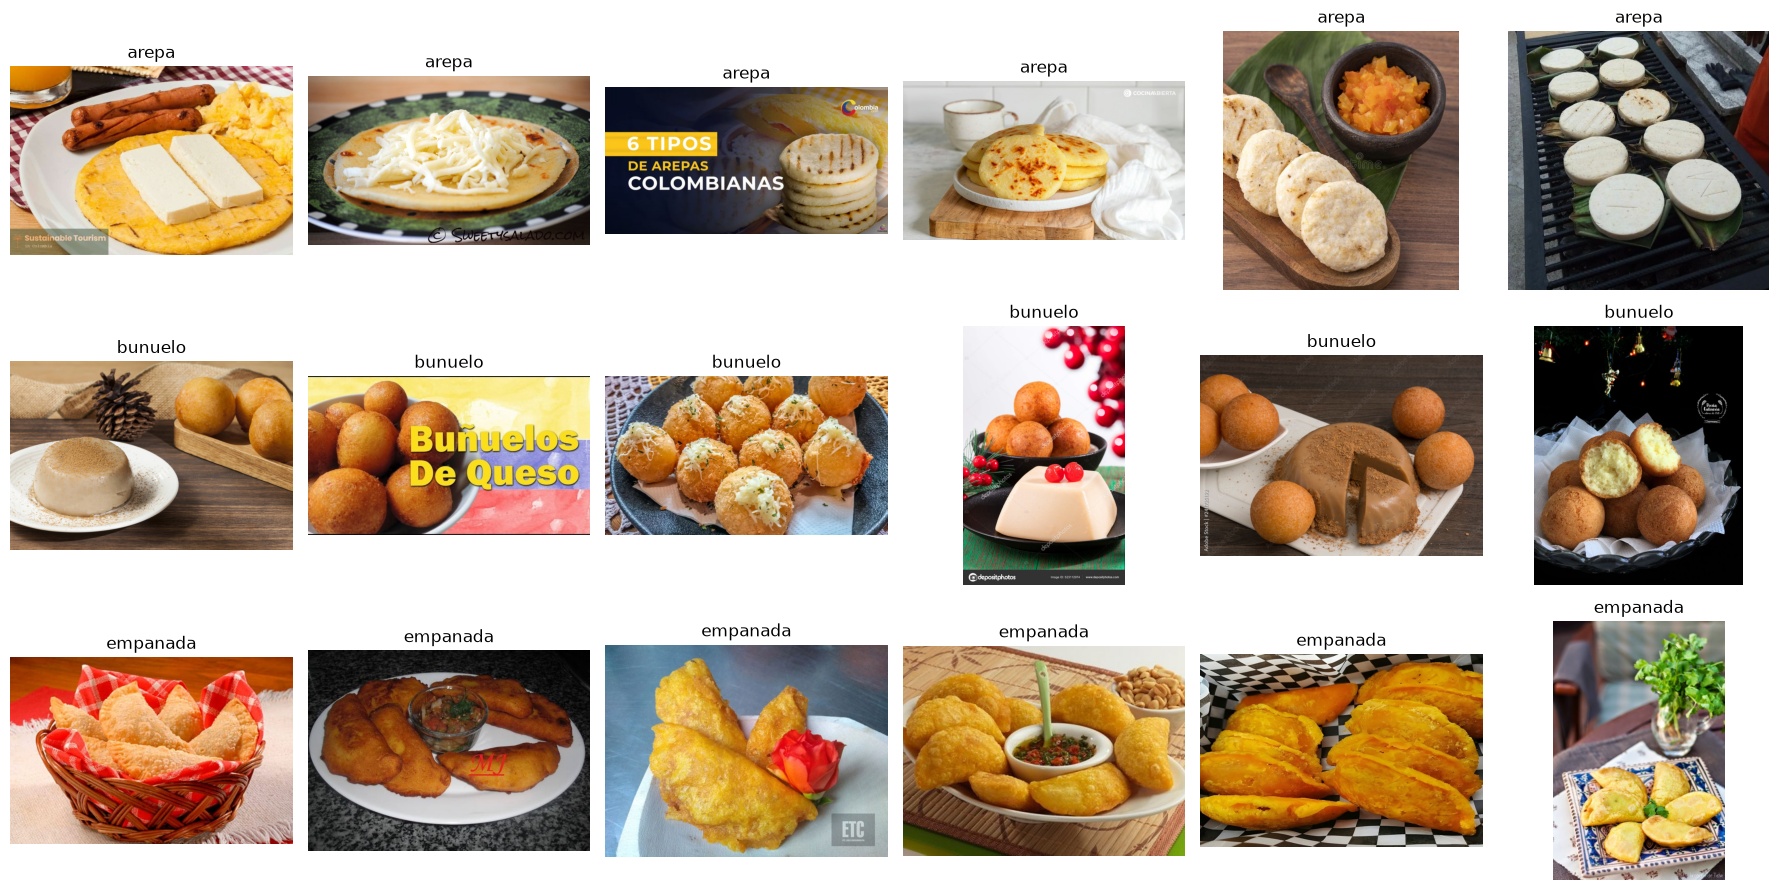

In [8]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                ax.imshow(Image.open(chosen[col]))
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

**Respuesta TODO 2 (dataset y limpieza)**

- **Cantidad final (carpeta `data_raw`):** 386 arepa, 378 bunuelo, 479 empanada (1243 imágenes). Es mucho más que las 100 a 150 por clase pedidas porque durante el desarrollo el notebook se ejecutó tres veces sin borrar `data_raw`, y la celda de descarga solo evita duplicados *exactos* (mismo hash), así que cada ejecución sumó las imágenes nuevas que devolvió el buscador. Primera ejecución: 128 / 126 / 159 imágenes. Esa acumulación también explica que haya fotos casi idénticas en varias carpetas (ver errores más abajo).
- **Validación técnica:** 0 imágenes inválidas eliminadas para TensorFlow.
- **Error más frecuente encontrado:** (1) la misma foto repetida con distinta resolución o recorte (el hash exacto no la detecta); (2) la consulta `empanada de pipian` falló en la primera ejecución con un `RequestError` de DuckDuckGo ("malformed headers"), por lo que la clase empanada quedó con 60 imágenes hasta que se añadieron más términos de búsqueda en lugar de subir `max_results`, como pide el taller; (3) fotos de recetas con texto o marca de agua y bandejas con varios productos.
- **Inspección:** no se hizo borrado manual imagen por imagen de las 1243; se revisaron muestras aleatorias como las de arriba. Limitación reconocida: puede haber etiquetas incorrectas sin detectar.

# 4. Separar train, validation y test (70 / 15 / 15)

In [9]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = sorted(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'arepa': 270, 'bunuelo': 264, 'empanada': 335}
validation {'arepa': 57, 'bunuelo': 56, 'empanada': 71}
test {'arepa': 59, 'bunuelo': 58, 'empanada': 73}


**Respuesta (comprobación conceptual).** Si usamos el conjunto de prueba una y otra vez para escoger épocas, `learning_rate` o capas a descongelar, esas decisiones terminan ajustadas al ruido particular de esas imágenes de test. Cada vez que miramos el test y cambiamos algo, el test deja de ser datos "nunca vistos": se vuelve parte del desarrollo, y su accuracy sobreestima el desempeño real en imágenes nuevas (es un tipo de overfitting al conjunto de evaluación). Por eso esas decisiones se toman con validation y el test se consulta una sola vez al final.

# 5. Datasets de Keras

In [10]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 869 files belonging to 3 classes.


Found 184 files belonging to 3 classes.


Found 190 files belonging to 3 classes.


['arepa', 'bunuelo', 'empanada']


# 6. Primer modelo: transfer learning con EfficientNetB0 congelada

In [11]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3: entrena la cabeza de clasificación

**Predicción antes de ejecutar:** esperamos que `train_accuracy` suba rápido (la base ya trae buenas características y solo se aprende una capa `Dense` de 3 neuronas sobre 1280 características). La señal de overfitting sería que `accuracy` siga subiendo mientras `val_accuracy` se estanca o baja y `val_loss` empieza a subir.

In [12]:
# TODO 3: configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10


/Users/juandavidsierraorozco/.venvs/keras/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/28 ━━━━━━━━━━━━━━━━━━━━ 5:32 12s/step - accuracy: 0.2188 - loss: 1.2458

 2/28 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.2031 - loss: 1.2752  

 3/28 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.2604 - loss: 1.2357

...

25/28 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.9712 - loss: 0.1275

26/28 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.9700 - loss: 0.1318

27/28 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.9699 - loss: 0.1318

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9701 - loss: 0.1315

28/28 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.9701 - loss: 0.1315 - val_accuracy: 0.9728 - val_loss: 0.1115


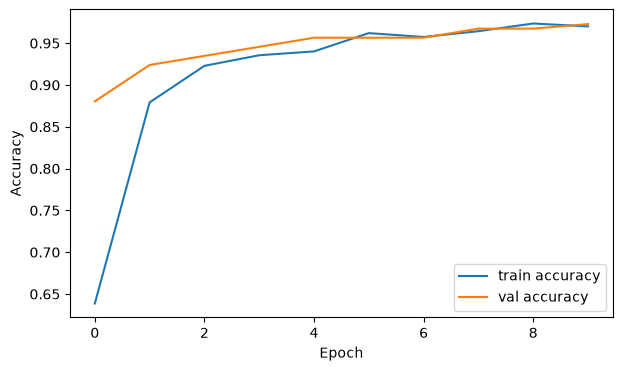

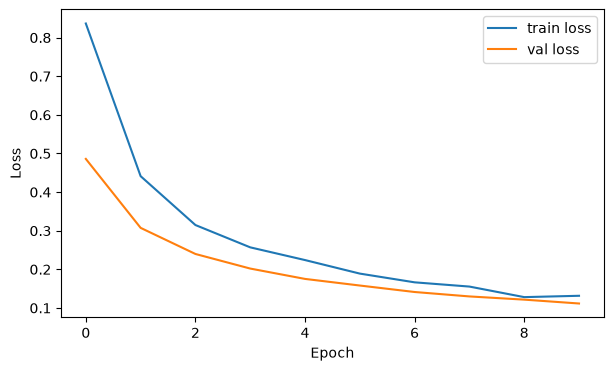

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

**Respuesta TODO 3 (primer entrenamiento, base congelada)**

- Resultados de las 10 épocas: `accuracy` pasó de 0.639 (época 1) a 0.970 (época 10) y `val_accuracy` de 0.880 a 0.973; `val_loss` bajó de 0.486 a 0.112 de forma continua.
- La predicción se cumplió: la accuracy de entrenamiento sube rápido porque solo se aprende la capa `Dense` sobre las características de ImageNet.
- No hay señal de overfitting: `val_loss` nunca subió, por eso `EarlyStopping` (patience=2) no se activó y el entrenamiento llegó a las 10 épocas. Un modelo más entrenado probablemente seguiría mejorando un poco.
- Nota: la accuracy de entrenamiento va por debajo de la de validación en las primeras épocas porque se calcula con data augmentation activo y como promedio durante la época.

# PARTE B: trabajo en casa

# 7. Evaluación del primer modelo (ahora sí en test)

In [14]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.9632


              precision    recall  f1-score   support

       arepa      0.950     0.966     0.958        59
     bunuelo      1.000     0.931     0.964        58
    empanada      0.947     0.986     0.966        73

    accuracy                          0.963       190
   macro avg      0.966     0.961     0.963       190
weighted avg      0.964     0.963     0.963       190



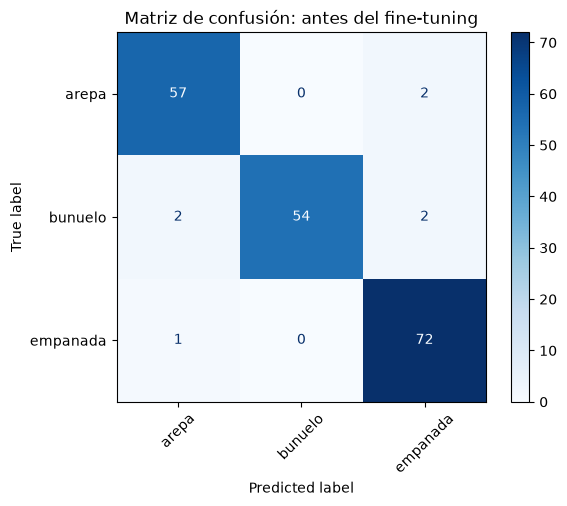

In [15]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión: antes del fine-tuning")
plt.show()

**Respuesta TODO 4 (evaluación del primer modelo en test)**

Test accuracy antes del fine-tuning: **0.9632** (190 imágenes de test, 7 errores).

1. **Mejor clase:** buñuelo por precision (1.000) y empanada por recall (0.986); la clase más débil en F1 fue arepa (0.958), aunque las tres clases están entre 0.958 y 0.966 de F1.
2. **Principal confusión:** buñuelo predicho como arepa (4 buñuelos con recall 0.931). Las arepas y las empanadas también se mezclan en ambos sentidos con 1 a 2 errores cada una (ver la matriz).
3. **¿La accuracy oculta algo?** Con 190 imágenes y 7 errores, la diferencia entre clases (por ejemplo 0.931 frente a 0.986 de recall) corresponde a 2 o 3 imágenes. Es una señal débil: con tan pocos errores no se puede afirmar que una clase sea realmente peor.
4. **Qué cambiaría primero en el dataset:** eliminar los duplicados casi idénticos (con un hash perceptual en lugar de solo el hash exacto) y hacer el split *antes* de mezclar búsquedas, para que ninguna foto repetida cruce de `train` a `test`; después limpiar manualmente fotos con varios productos.

# 8. Fine-tuning

Se descongelan las últimas capas del backbone, con BatchNormalization siempre congelada, y se recompila con `learning_rate` mucho menor.

In [16]:
base_model.trainable = True

# TODO 5: cuántas capas finales adaptar (punto de partida sugerido: ~20)
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


In [17]:
# TODO 5: recompilar y continuar el entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stopping_ft],
)

Epoch 1/8


/Users/juandavidsierraorozco/.venvs/keras/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/28 ━━━━━━━━━━━━━━━━━━━━ 8:09 18s/step - accuracy: 0.9375 - loss: 0.2072

 2/28 ━━━━━━━━━━━━━━━━━━━━ 22s 853ms/step - accuracy: 0.9688 - loss: 0.1521

 3/28 ━━━━━━━━━━━━━━━━━━━━ 23s 956ms/step - accuracy: 0.9688 - loss: 0.1463

...

25/28 ━━━━━━━━━━━━━━━━━━━━ 1s 448ms/step - accuracy: 0.9887 - loss: 0.0587

26/28 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - accuracy: 0.9892 - loss: 0.0582

27/28 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step - accuracy: 0.9896 - loss: 0.0580

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.9896 - loss: 0.0581

28/28 ━━━━━━━━━━━━━━━━━━━━ 15s 510ms/step - accuracy: 0.9896 - loss: 0.0581 - val_accuracy: 0.9783 - val_loss: 0.0695


# 9. Comparación antes vs. después

In [18]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.9632
Después del fine-tuning: 0.9737
Diferencia              : +0.0105


              precision    recall  f1-score   support

       arepa      0.950     0.966     0.958        59
     bunuelo      1.000     0.966     0.982        58
    empanada      0.973     0.986     0.980        73

    accuracy                          0.974       190
   macro avg      0.974     0.973     0.973       190
weighted avg      0.974     0.974     0.974       190



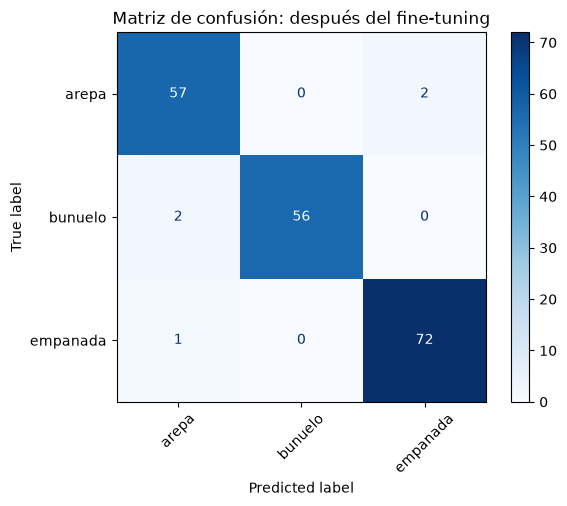

In [19]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión: después del fine-tuning")
plt.show()

# 10. Análisis de errores

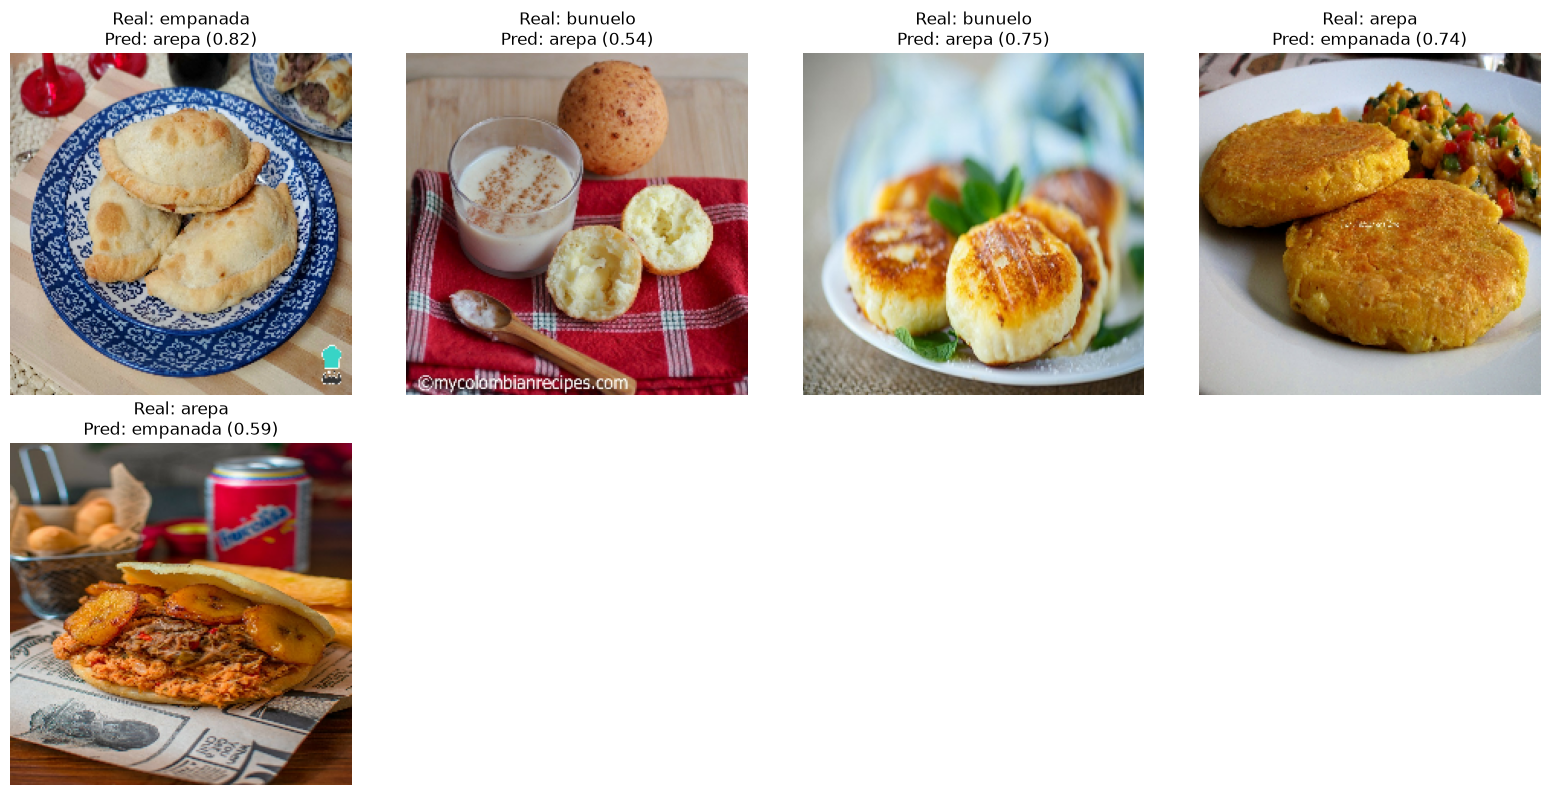

In [20]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

Errores en test: 5 de 190
Errores en validation: 4 de 184


1 ('test', 'arepa/0016.jpg', 'arepa', 'empanada', 0.5923745632171631)
2 ('test', 'arepa/0174.jpg', 'arepa', 'empanada', 0.7389907836914062)
3 ('test', 'bunuelo/0211.jpg', 'bunuelo', 'arepa', 0.7460774779319763)
4 ('test', 'bunuelo/0371.jpg', 'bunuelo', 'arepa', 0.5442784428596497)
5 ('test', 'empanada/0137.jpg', 'empanada', 'arepa', 0.8230333924293518)
6 ('validation', 'arepa/0033.jpg', 'arepa', 'empanada', 0.7466664910316467)
7 ('validation', 'arepa/0046.jpg', 'arepa', 'empanada', 0.7389907836914062)
8 ('validation', 'arepa/0161.jpg', 'arepa', 'empanada', 0.7466664910316467)


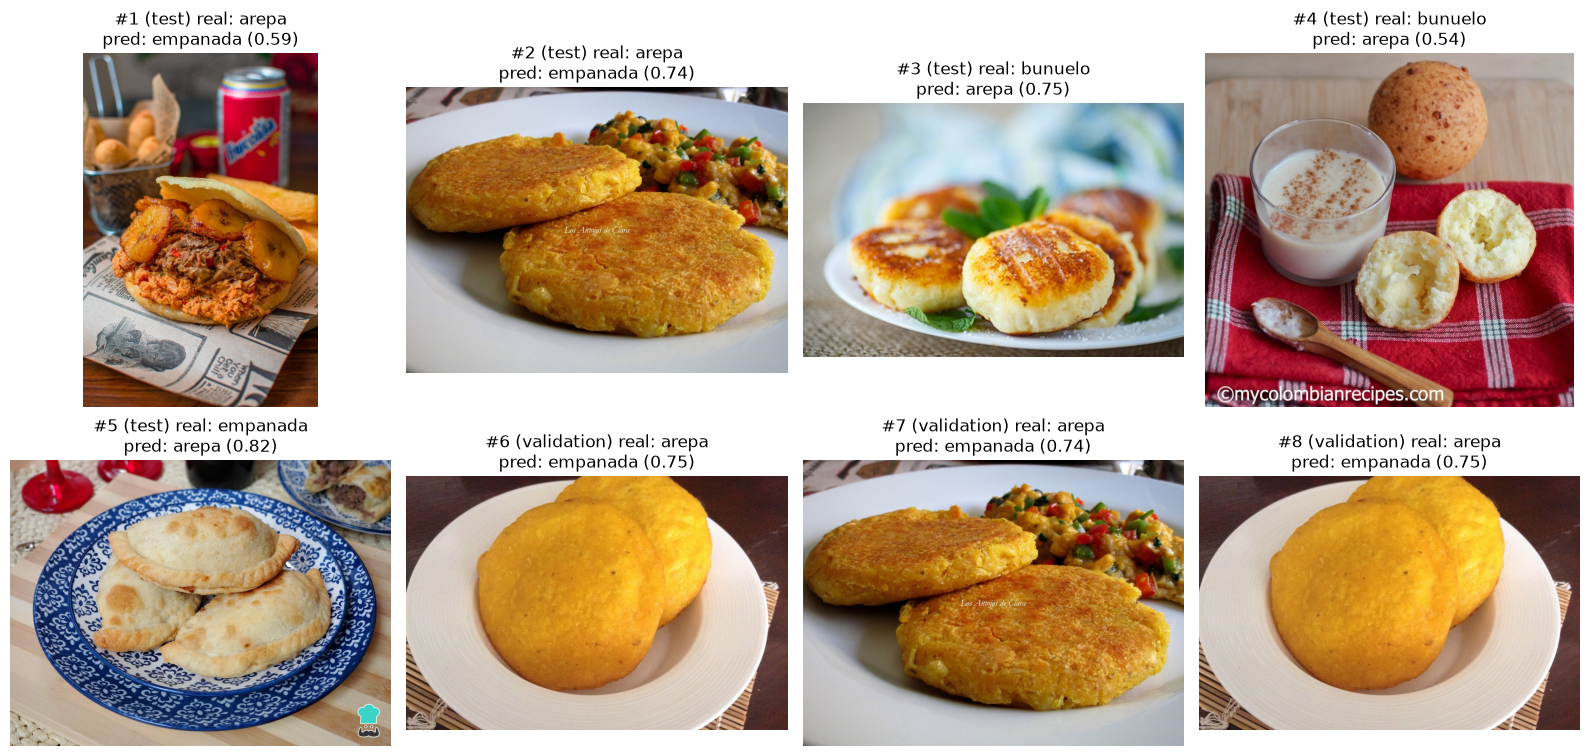

In [21]:
# Errores del modelo ajustado con nombre de archivo, para la tabla del TODO 6.
# Se listan primero los de test y, si no llegan a 5, se completan con errores de validation.
def list_errors(split, ds):
    yt, yp, pr = get_predictions(model, ds)
    files = sorted(Path(SPLIT_DIR/split).rglob("*.jpg"), key=lambda p: (class_names.index(p.parent.name), p.name))
    return [(split, f"{files[i].parent.name}/{files[i].name}", class_names[yt[i]], class_names[yp[i]], float(pr[i][yp[i]])) for i in range(len(yt)) if yt[i] != yp[i]], len(yt)

wrong_test, n_test = list_errors("test", test_ds)
wrong_val, n_val = list_errors("validation", val_ds)
print(f"Errores en test: {len(wrong_test)} de {n_test}")
print(f"Errores en validation: {len(wrong_val)} de {n_val}")
# Si aun así hay menos de 5 errores, se completan con los aciertos de test de menor confianza ("casi errores").
yt_, yp_, pr_ = get_predictions(model, test_ds)
files_ = sorted(Path(SPLIT_DIR/"test").rglob("*.jpg"), key=lambda p: (class_names.index(p.parent.name), p.name))
ok_ = sorted([(float(pr_[i][yp_[i]]), i) for i in range(len(yt_)) if yt_[i] == yp_[i]])
near = [("test (acierto dudoso)", f"{files_[i].parent.name}/{files_[i].name}", class_names[yt_[i]], class_names[yp_[i]], c) for c, i in ok_[:max(0, 5 - len(wrong_test) - len(wrong_val))]]
sel = (wrong_test + wrong_val + near)[:8]
for k, w in enumerate(sel, 1):
    print(k, w)
if sel:
    nr = int(np.ceil(len(sel)/4))
    plt.figure(figsize=(16, 4*nr))
    for k,(sp,f,t,p,c) in enumerate(sel):
        ax = plt.subplot(nr,4,k+1)
        ax.imshow(Image.open(SPLIT_DIR/sp.split()[0]/f)); ax.axis("off")
        ax.set_title(f"#{k+1} ({sp}) real: {t}\npred: {p} ({c:.2f})")
    plt.tight_layout(); plt.show()

## TODO 6: análisis de errores y conclusiones

El modelo ajustado cometió **5 errores en test (de 190) y 4 en validation (de 184)**. Se analizan 8 (los 5 de test y 3 de validation; la imagen #6 y #8 son la misma foto, y #2 y #7 también, lo que ya es una pista de *data leakage*).

| # | Imagen | Clase real | Predicción (confianza) | Causa probable | Cómo mejorarlo |
|---|---|---|---|---|---|
| 1 | test, arepa/0016 | arepa | empanada (0.59) | Fondo con mucho ruido (lata, canasta con buñuelos, periódico) y la arepa va rellena y doblada como un sándwich; parece una empanada o producto relleno. Objeto parcialmente ocluido. | Más fotos de arepas rellenas, recorte de la región del plato, más aumento de datos de zoom. |
| 2 | test, arepa/0174 | arepa | empanada (0.74) | Arepa de choclo/queso muy dorada y con textura rugosa, parecida a una empanada frita; clase visualmente similar. Esta misma foto aparece también en validation (#7). | Eliminar duplicados; añadir arepas de choclo con etiquetas claras. |
| 3 | test, bunuelo/0211 | bunuelo | arepa (0.75) | Posible etiqueta incorrecta o clase ambigua: son tortitas planas doradas con menta, que no parecen buñuelos colombianos (esferas). Discos planos se parecen a arepas. | Revisar y quitar la imagen o reetiquetar; agregar un criterio de limpieza manual. |
| 4 | test, bunuelo/0371 | bunuelo | arepa (0.54) | Buñuelo partido (miga blanca visible) junto a vaso de natilla y manta roja; fondo muy distinto de los buñuelos típicos. Confianza baja, error razonable. Tiene marca de agua. | Más imágenes de buñuelos abiertos y en fondos variados; recortar el texto. |
| 5 | test, empanada/0137 | empanada | arepa (0.82) | Empanadas horneadas, pálidas y sin el color frito, apiladas en un plato con otro plato al fondo. La empanada horneada es de otro tipo que las fritas dominantes en el dataset (sesgo del dataset). Error con alta confianza, el más preocupante. | Equilibrar variantes (fritas/horneadas) y añadir empanadas horneadas. |
| 6 | validation, arepa/0033 | arepa | empanada (0.75) | Arepa gruesa y redonda, muy amarilla (probablemente de choclo) sobre plato blanco; las dos piezas apiladas con bordes redondeados recuerdan una empanada frita. | Más ejemplos de arepa gruesa vista de frente. |
| 7 | validation, arepa/0046 | arepa | empanada (0.74) | Misma foto que #2 en versión duplicada, por lo que repite el error (duplicado entre splits). | Deduplicar con hash perceptual antes de dividir. |
| 8 | validation, arepa/0161 | arepa | empanada (0.75) | Duplicado de #6. | Igual que #6. |

### Conclusiones

1. **Qué aprendí al construir el dataset:** que el buscador no entrega un dataset limpio: devuelve las mismas fotos repetidas, imágenes con texto, recetas con varios platos y a veces productos de otra categoría. Construir el dataset toma más trabajo que entrenar el modelo.
2. **Principal problema de calidad:** los duplicados casi idénticos (mismas fotos en `train`, `validation` y `test`) y las etiquetas dudosas. Las parejas #2/#7 y #6/#8 prueban que hubo fugas entre splits, así que el accuracy de 0.96 a 0.97 probablemente está **ligeramente inflado**.
3. **Cambio con el fine-tuning:** la accuracy en test pasó de **0.9632 a 0.9737** (+0.0105, es decir, 2 imágenes más de 190 acertadas). `val_loss` bajó de 0.103 a 0.070 durante el ajuste.
4. **¿Ayudó el fine-tuning?** Un poco, pero la mejora es muy pequeña y no es estadísticamente distinguible del azar con un test de 190 imágenes (con 2 imágenes de diferencia). Tiene sentido que ayude poco: las comidas colombianas están cerca del dominio de ImageNet (que ya trae clases como *bagel*, *pretzel*, *plate*) y la base congelada ya extrae características suficientes; descongelar las 15 capas finales con `lr=1e-5` apenas las ajusta.
5. **Qué mejoraría primero:** los **datos**. Eliminar duplicados con hash perceptual, hacer el split por origen (no por archivo) para evitar leakage, revisar etiquetas manualmente y equilibrar variantes (empanada frita/horneada, arepa de choclo/rellena). Después, más épocas; la arquitectura no parece ser el cuello de botella.

**Decisión sobre `N_UNFROZEN`:** se usó el valor de partida sugerido (20, que deja 15 capas realmente entrenables porque las BatchNormalization se mantienen congeladas, de 238 capas del backbone). No se comparó con otros valores usando validation, por falta de tiempo de cómputo en CPU; es una limitación.

### Cierre conceptual: feature extraction, fine-tuning y entrenar desde cero

- **Feature extraction (base congelada):** el conocimiento inicial viene de ImageNet (más de un millón de imágenes, 1000 clases) y queda fijo. Solo se aprenden los pesos de la cabeza nueva: `Dense(3)` sobre 1280 características, es decir unos 3.8 mil parámetros, frente a los cerca de 4 millones del backbone, que no cambian.
- **Fine-tuning:** parte del mismo conocimiento de ImageNet, pero se descongelan las últimas capas del backbone y se entrenan junto con la cabeza con un `learning_rate` muy pequeño (1e-5) para adaptar las características de alto nivel a arepas, empanadas y buñuelos sin destruir lo aprendido. Se aprenden la cabeza y esas capas finales; las capas iniciales (bordes, texturas) y las BatchNormalization siguen fijas.
- **CNN desde cero:** no hay conocimiento previo; todos los pesos se inicializan al azar y se aprenden solo con nuestras ~860 imágenes de entrenamiento. Con tan pocos datos tendería a sobreajustar y a quedar muy por debajo de las otras dos opciones.